# IntelliSense Backtest Analysis
Compare the performance of **Fixed Q-table**, **Q-learning**, and **DQN** strategies across different tickers.

---

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import json
import os
from IPython.display import display, Markdown

# Set plotting style
plt.style.use('seaborn-v0_8-darkgrid')

def plot_ticker(ticker):
    results_dir = 'test_results'
    methods = ['Fixed_Q_table', 'DQN', 'Q_learning']
    colors = {'Fixed_Q_table': '#1f77b4', 'DQN': '#2ca02c', 'Q_learning': '#ff7f0e'}
    
    plt.figure(figsize=(14, 7))
    
    has_data = False
    all_dfs = {}
    
    for method in methods:
        filename = f"{ticker}_{method}_history.json"
        filepath = os.path.join(results_dir, filename)
        
        if os.path.exists(filepath):
            has_data = True
            with open(filepath, 'r') as f:
                data = json.load(f)
            
            df = pd.DataFrame(data)
            if not df.empty:
                df['date'] = pd.to_datetime(df['date'])
                all_dfs[method] = df
                
                # Calculate % return for normalization
                initial_val = df['portfolio_value'].iloc[0]
                df['return'] = (df['portfolio_value'] - initial_val) / initial_val * 100
                
                # Use dashed line for Fixed Q-table to show overlap
                linestyle = '--' if method == 'Fixed_Q_table' else '-'
                linewidth = 3.0 if method == 'Fixed_Q_table' else 2.5
                alpha = 0.8 if method == 'Fixed_Q_table' else 1.0
                
                plt.plot(df['date'], df['portfolio_value'], 
                         label=f"{method.replace('_', ' ')}", 
                         color=colors.get(method), 
                         linewidth=linewidth,
                         linestyle=linestyle,
                         alpha=alpha)
    
    if has_data:
        plt.title(f'{ticker} Strategy Comparison', fontsize=18, fontweight='bold')
        plt.xlabel('Date', fontsize=12)
        plt.ylabel('Portfolio Value ($)', fontsize=12)
        plt.legend(fontsize=12)
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()
        
        # --- Display LLM Insights ---
        display(Markdown(f"### 🧠 {ticker} Quarterly LLM Insights"))
        
        # Use DQN history (or whichever exists) to show insights
        best_method = 'DQN' if 'DQN' in all_dfs else list(all_dfs.keys())[0]
        history_df = all_dfs[best_method]
        
        if 'llm_analysis' in history_df.columns:
            # Group by duplicate analysis text to show one per quarter
            insights = history_df[history_df['llm_analysis'] != ""].drop_duplicates(subset=['llm_analysis'])
            
            for _, row in insights.iterrows():
                date_str = row['date'].strftime('%Y-%m-%d')
                analysis = row['llm_analysis']
                # Show first 500 chars + clean format
                display(Markdown(f"**{date_str}**: {analysis}"))
                display(Markdown("---"))
        else:
            print("⚠️ No LLM analysis text found in history. Ensure you've run the backtest with the latest code.")
            
    else:
        print(f"No data found for {ticker} in {results_dir}")

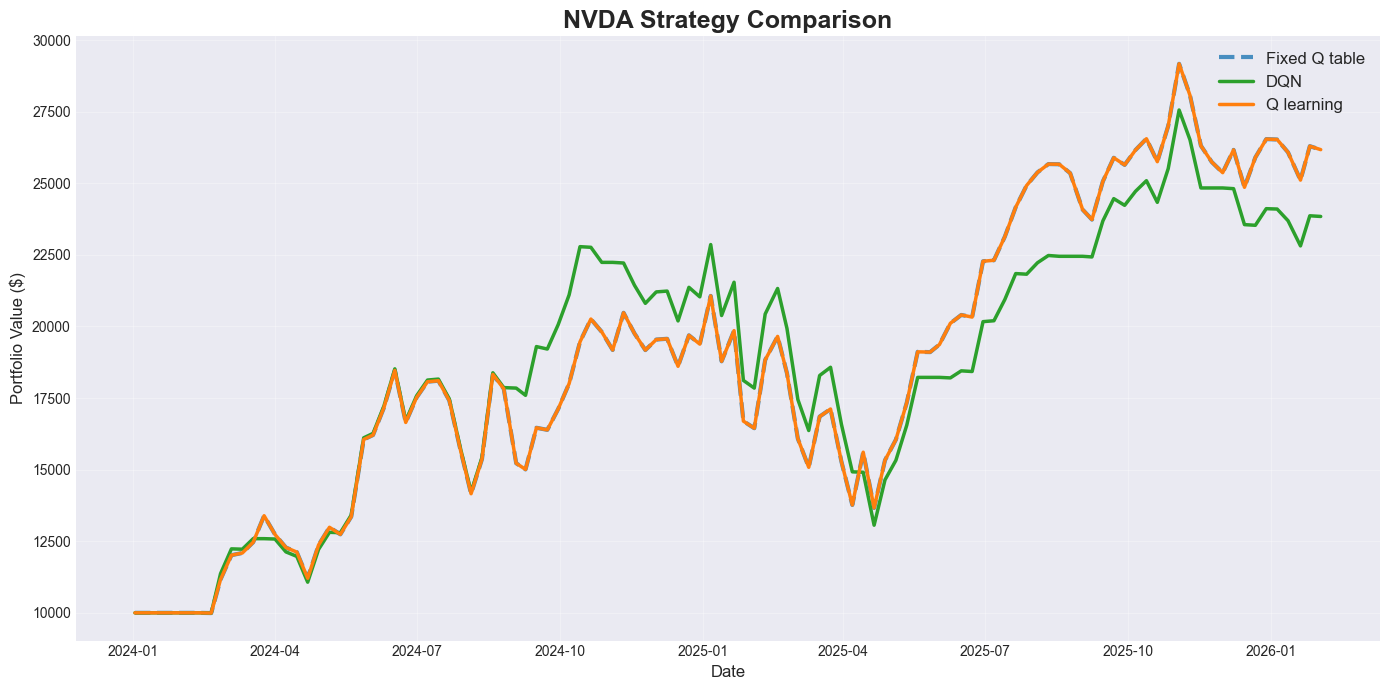

### 🧠 NVDA Quarterly LLM Insights

**2024-02-20**: ### 1) Revenue and Growth Trajectory  
In 2023-Q4, revenue was **$6.05B** (+2% QoQ, **-21% YoY**), reflecting a cyclical trough in consumer/visualization markets while Data Center remained structurally stronger. **Data Center $3.62B** (-6% QoQ, +11% YoY) showed a temporary digestion phase at hyperscalers, but with clear product-cycle momentum (H100 ramp). **Gaming $1.83B** (+16% QoQ, -46% YoY) improved sequentially as channel inventory correction neared completion—an important recurring pattern: NVIDIA’s consumer segments tend to rebound sharply once inventory clears.  

### 2) Macro Environment Impact  
With **inflation ~4.1%** and **Fed funds ~5.33%**, tighter financial conditions pressured discretionary demand (PC/gaming) and encouraged cloud customers to “pause/recalibrate” capex timing. However, low **unemployment (3.8%)** and ongoing cloud migration supported enterprise AI spend, making Data Center more resilient than consumer segments.  

### 3) Key Business Drivers and Catalysts  
Primary catalysts are the **H100 adoption curve**, accelerating **generative AI** workloads, and attach opportunities in **networking (InfiniBand/Ethernet)** needed to scale multi-node AI. A second durable driver is the shift toward **software and AI services** (DGX Cloud, AI Enterprise, NeMo/BioNeMo), expanding monetization beyond chips.  

### 4) Risk Factors and Headwinds  
Key risks include **hyperscaler capex lumpiness** (timing-driven volatility), **China-related demand softness**, and continued weakness in ProViz/gaming if macro tightness persists. Execution risk rises as NVIDIA expands into cloud services (operational complexity, partner dependence).  

### 5) Forward-Looking Sentiment  
Management tone is strongly constructive: AI is described as at an **inflection point**, with expectations for **Data Center growth to accelerate through the year**. Recurring trend: near-term pauses in customer ordering are framed as timing issues, followed by renewed ramps tied to major platform transitions (e.g., A100→H100).

---

**2024-05-06**: ### 1) Revenue and Growth Trajectory  
In FY2024 Q1, revenue was **$7.19B**, **+19% QoQ** but **-13% YoY**, reflecting a sharp sequential rebound as gaming and pro visualization worked through channel inventory corrections while **data center hit a record $4.28B** (**+18% QoQ, +14% YoY**). A recurring pattern across periods is NVIDIA’s ability to re-accelerate growth after digestion phases: earlier softness in consumer-facing segments is followed by recoveries tied to new product cycles (RTX 40/Ada) and normalization of channel inventory. In later historical context (FY2025 Q4), scale is dramatically higher (**$57.0B revenue; $31.9B net income**), reinforcing a multi-quarter trend of **AI-led step-change expansion** and operating leverage.

### 2) Macro Environment Impact  
With **Fed funds ~5.33%** and **10Y ~4.16%**, capital is expensive, typically pressuring discretionary spend (PC/gaming) and enterprise IT budgets. However, low unemployment and moderating inflation support baseline demand, while AI infrastructure remains a “must-fund” priority for hyperscalers and leading enterprises—partially insulating NVIDIA from tighter financial conditions.

### 3) Key Business Drivers and Catalysts  
Primary driver is **generative AI** accelerating training and inference demand for **Hopper (H100)** plus a widening platform pull-through (DGX systems, DGX Cloud, AI Foundations, Triton, networking via Mellanox/InfiniBand, BlueField DPUs). Product cadence (L4/L40/Grace Hopper) and expanding CSP availability are near-term catalysts.

### 4) Risk Factors and Headwinds  
Key risks include supply constraints/lead times for flagship GPUs, customer concentration among CSPs, potential digestion cycles after large AI capex waves, and continued softness in general-purpose CPU infrastructure. Gaming remains sensitive to consumer spending and prior-cycle inventory dynamics; automotive faces China NEV demand variability.

### 5) Forward-Looking Sentiment  
Management tone is strongly constructive: AI demand is described as **broad-based and accelerating**, with confidence in networking and enterprise momentum. Recurring trend: NVIDIA pairs hardware leadership with an expanding software/services layer, increasing switching costs and sustaining growth even as non-AI segments cycle.

---

...

---

**2025-11-03**: ### 1. Revenue and Growth Trajectory  
NVDA’s growth remains overwhelmingly Data Center-led. In 2025-Q3, revenue reached **$35.1B** (+17% QoQ, +94% YoY) with **Data Center at $30.8B** (+17% QoQ, +112% YoY), reflecting sustained hyperscaler and “AI factory” buildouts. A recurring pattern across recent quarters is **beat-and-raise execution** alongside rapid platform transitions: Q3 exceeded guidance ($32.5B) and Q4 guided to **$37.5B ±2%**, implying continued sequential expansion. Historical fundamentals show strong operating leverage and cash generation (2025-Q4: **$57.0B revenue, $31.9B net income, $23.8B operating cash flow**), while capital returns remain aggressive (large negative financing cash flow), signaling confidence in durability.

### 2. Macro Environment Impact  
With policy rates ~**4.3%** and the 10Y ~**4.26%**, tighter financial conditions typically pressure cyclical tech demand. NVDA is partially insulated because spending is shifting from discretionary IT to **strategic AI infrastructure**, though higher rates can still slow enterprise deal cycles and constrain smaller customers’ funding.

### 3. Key Business Drivers and Catalysts  
Primary drivers are **Hopper (H200) ramp**, expanding **networking attach** (InfiniBand/Spectrum-X), and the **Blackwell transition** (early shipments, MLPerf leadership, CSP launches). A recurring catalyst is NVIDIA’s **software flywheel** (CUDA + NIM/AI Enterprise), with software/services annualizing toward **>$2B**, improving stickiness and monetization beyond silicon.

### 4. Risk Factors and Headwinds  
Key headwinds include **supply constraints** (explicitly limiting Gaming in Q4), **gross margin dilution** from complex systems and Blackwell ramp (guiding low-70s), and **China/export-control exposure** (competitive, structurally lower mix than pre-controls). Concentration risk (CSPs ~half of DC) and potential digestion cycles remain watch items.

### 5. Forward-Looking Sentiment  
Management tone is strongly bullish: demand “**staggering**,” visibility improving, and Blackwell revenue expected to exceed prior estimates. The recurring trend is NVIDIA converting architectural leadership into **multi-quarter demand backlogs**, with near-term results gated more by **supply and mix** than end-demand.

---

**2026-02-02**: ### 1. Revenue and Growth Trajectory  
NVDA’s growth remains overwhelmingly data-center led. Management reported Q4 revenue of **$39.3B (+12% QoQ, +78% YoY)** and FY25 revenue of **$130.5B (+114% YoY)**, with **data center at $35.6B in Q4 (+16% QoQ, +93% YoY)** and **$115.2B for FY25**. A recurring pattern across recent quarters is **beat-and-raise dynamics driven by new architecture ramps**—this quarter highlighted by **Blackwell’s $11B** in first-ramp revenue, described as the fastest in company history. Profitability remains exceptional (historical context shows **$57.0B total revenue, $31.9B net income**), though margins are temporarily pressured by mix and ramp costs.

### 2. Macro Environment Impact  
With **Fed funds ~3.9%** and **10Y ~4.1%**, higher discount rates can compress multiples, but operational demand is less rate-sensitive because hyperscalers and sovereigns are treating AI infrastructure as strategic capex. **Unemployment ~4.45%** suggests a still-resilient economy, supportive of enterprise AI spend, while inflation data is incomplete but CPI level implies ongoing cost vigilance.

### 3. Key Business Drivers and Catalysts  
Core catalysts are (1) **Blackwell scale-up** (100k+ GPU clusters), (2) accelerating **inference/test-time scaling** (management cites up to **100x compute per task** for reasoning), and (3) expanding **full-stack software/networking attach** (networking attach **>75%**, Spectrum-X/Cisco channel). Automotive is an emerging leg with **~$5B FY26E** commentary.

### 4. Risk Factors and Headwinds  
Key headwinds recur: **export controls/China share capped**, **competitive intensity in China**, and **gross margin dilution during major ramps** (low-70s near-term). Concentration risk persists with **CSPs ~50% of data-center revenue**. Gaming volatility also repeats—Q4 decline tied to **supply constraints**, not demand.

### 5. Forward-Looking Sentiment  
Tone is strongly bullish: management frames demand as structural (pretraining → post-training → inference) and expects **networking to re-accelerate in Q1** and **gross margin recovery to mid-70s late FY26** as Blackwell matures and costs improve.

---

In [23]:
plot_ticker('NVDA')

In [ ]:
plot_ticker('TSLA')

In [ ]:
plot_ticker('AAPL')

In [ ]:
plot_ticker('MSFT')

In [ ]:
plot_ticker('GOOGL')

In [ ]:
plot_ticker('AMZN')

In [ ]:
plot_ticker('META')

In [ ]:
plot_ticker('TSM')

In [ ]:
plot_ticker('ASML')